### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Eric Alejandro Moro Rebollo

* **Matrícula:** A01840718

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [9]:
# Incluye a continuación todas librerías que consideres necesarias:

# En Colab imbalanced-learn ya viene instalada; si no, descomenta la siguiente línea:
# !pip install imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy import mean, std

import sklearn
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (make_scorer, accuracy_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, auc)

from imblearn.metrics import geometric_mean_score, classification_report_imbalanced

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA Maestria en Inteligencia Artificial/MNA-IA y Aprendizaje Automatico TC4058.10/Semana 4"
os.chdir(DIR)

**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [12]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [13]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **1a)** El problema está muy cargado hacia una sola clase: de los 937 recortes de imagen, solo 41 tienen derrame (4.4%). Con esa proporción, un "modelo" que conteste siempre "no hay derrame" acierta alrededor del 95.6% de las veces y aun así no detecta un solo derrame. En el Ejercicio 3 se ve justamente eso: el clasificador ingenuo saca 0.9575 de exactitud y su matriz de confusión deja escapar los 28 derrames del entrenamiento. La exactitud se llena con los aciertos de la clase mayoritaria y esconde que el modelo es inútil para lo que nos importa.

  La media geométrica se calcula como $G = \sqrt{\text{sensibilidad} \times \text{especificidad}}$, es decir, combina qué tan bien se detectan los derrames y qué tan bien se reconoce el mar limpio. Al ser un producto, basta con que una de las dos sea cero para que la G-mean sea cero, así que no se puede "maquillar" ignorando la clase pequeña. Además pesa igual a las dos clases, que es justo el supuesto de este ejercicio (FP y FN igual de costosos). No es casualidad que Kubat, Holte y Matwin (1998) la usaran en el artículo original de estos datos.

* **1b)** Un Falso Positivo es cuando el modelo marca derrame en una imagen donde no lo hay. En radar satelital esto pasa mucho con los llamados *look-alikes*: zonas de mar en calma por falta de viento, manchas de algas o lluvia, que se ven oscuras igual que el petróleo (Kubat et al., 1998). Las implicaciones son sobre todo operativas: mandar un avión o helicóptero a revisar, horas de personal y combustible para nada. Si pasa muy seguido, el riesgo más serio es la fatiga de alarmas: el equipo deja de confiar en el sistema y empieza a ignorar sus avisos, incluidos los verdaderos. Y si el sistema se usa para identificar al barco responsable, se podría señalar a una embarcación que no tuvo nada que ver.

* **1c)** Un Falso Negativo es cuando sí hay derrame y el modelo dice que el mar está limpio. Aquí el problema crece con el tiempo: el petróleo se sigue extendiendo, puede llegar a la costa, daña fauna y ecosistemas, y la limpieza sale mucho más cara entre más tarde empieza. También se pierde la oportunidad de identificar y multar al responsable mientras todavía está en la zona, y la autoridad queda expuesta legal y públicamente por no haber detectado algo que su sistema "vigilaba". Por eso, aunque en este ejercicio supongamos que FP y FN cuestan lo mismo, en la realidad un FN es mucho más grave, cosa que se cuantifica en el Ejercicio 7.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [14]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


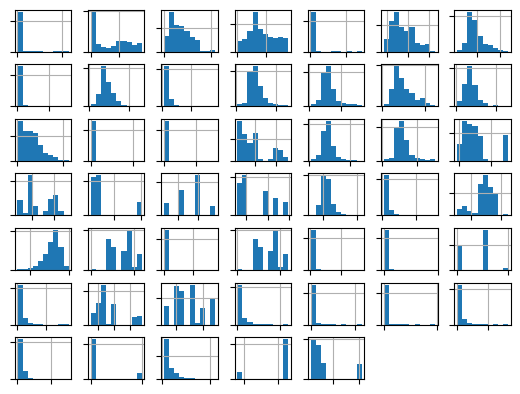

In [15]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [16]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **2a)** Yeo-Johnson es una transformación de potencia que busca que cada variable quede más simétrica y más parecida a una distribución normal, es decir, corrige el sesgo y de paso estabiliza la varianza. Para cada columna se estima un parámetro $\lambda$ por máxima verosimilitud, eligiendo el valor que hace que los datos transformados se acerquen más a una normal (Yeo y Johnson, 2000). Para valores positivos o cero aplica $\frac{(x+1)^{\lambda}-1}{\lambda}$ (o $\ln(x+1)$ si $\lambda=0$), y para valores negativos usa una versión reflejada con exponente $2-\lambda$.

  En estos datos tiene mucho sentido: hay columnas con sesgos enormes (por ejemplo `f_18` tiene una asimetría cercana a 21 y `f_6` llega a valores de 71 millones), y eso afecta a modelos como la regresión logística, donde unos pocos valores extremos pueden dominar el ajuste. En el pipeline la transformación va dentro del `ColumnTransformer`, así que el $\lambda$ se estima solo con los datos de entrenamiento de cada partición y no hay filtrado de información.

* **2b)** La diferencia principal está en qué datos aceptan. Box-Cox (Box y Cox, 1964) usa $x^{\lambda}$ y $\ln(x)$, así que solo funciona con valores estrictamente positivos. Yeo-Johnson es una extensión que acepta ceros y negativos sin necesidad de sumar una constante. En este dataset eso es decisivo: de las 47 columnas que usamos, 4 tienen valores negativos (`f_26`, `f_28`, `f_30` y `f_31`) y otras 11 tienen ceros. Con Box-Cox habría que desplazar cada una de esas 15 columnas por una constante elegida a mano; con Yeo-Johnson se aplica la misma transformación a todas sin revisar el signo de cada columna (scikit-learn developers, s.f.).

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [17]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* **3a)** Probé las cinco estrategias del `DummyClassifier` con `n_splits` de 3, 5, 7 y 10 (celda adicional). Con `most_frequent`, `prior` y `constant` la G-mean sale exactamente 0: las tres predicen siempre la misma clase, así que la sensibilidad o la especificidad queda en cero y el producto se anula. `stratified` predice positivo al azar solo en ~4% de los casos, casi nunca coincide con un derrame real y su G-mean queda entre 0 y 0.07. La que tiene sentido es **`uniform`**: lanza una moneda al aire para cada imagen, así que en promedio acierta la mitad de los derrames y la mitad del mar limpio, y su G-mean teórica es $\sqrt{0.5 \times 0.5} = 0.5$. Es la referencia ingenua más exigente para esta métrica y no usa nada de información de las variables.

  Para `n_splits` me fijé en cuántos derrames quedan en cada partición de validación, porque en el entrenamiento solo hay 28. Con 10 particiones quedan 2 o 3 derrames por partición y el resultado brinca mucho (G-mean 0.493, std 0.163). Con 3 particiones hay más positivos, pero cada modelo se entrena con solo dos tercios de los datos y el promedio se aleja del valor teórico (0.551). Con 7 la desviación fue la más baja (0.081). Me quedé con **`n_splits=5`**: deja de 5 a 6 derrames por partición, el promedio (0.508) es el más cercano al 0.5 teórico y, sobre todo, es el mismo esquema de validación cruzada que se usa en la celda "Código-1" y en el Ejercicio 5, así que las comparaciones contra el modelo base quedan en igualdad de condiciones.

* **3b)** Con `strategy='uniform'` y `n_splits=5` el modelo base obtiene una **G-mean de 0.508** (std 0.137). Ese es el umbral: cualquier modelo que no supere aproximadamente **0.51** de G-mean está subentrenado, porque no es mejor que tirar una moneda.

* **3c)** Con la exactitud, la estrategia ingenua más fuerte es `most_frequent`, que siempre predice "no hay derrame". Su exactitud es **0.9575**, que no es otra cosa que la proporción de imágenes sin derrame en el entrenamiento (631 de 659). Ese sería el umbral a superar. La matriz de confusión (celda siguiente, obtenida con validación cruzada sobre el entrenamiento) muestra el problema: acierta las 631 imágenes limpias y falla los 28 derrames, todos como falsos negativos. Un 95.75% de exactitud con 0% de derrames detectados.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [18]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


### **Celda adicional: exploración de "strategy" y "n_splits" para el DummyClassifier**
Pruebo las cinco estrategias con varios valores de `n_splits` para justificar la selección del inciso 3a.

In [19]:
# Exploración de estrategias y número de divisiones para el modelo base:
estrategias = ['most_frequent', 'prior', 'stratified', 'uniform', 'constant']
for estrategia in estrategias:
    for k in [3, 5, 7, 10]:
        cv_tmp = RepeatedStratifiedKFold(n_splits=k, n_repeats=3, random_state=7)
        extra = {'constant': 1} if estrategia == 'constant' else {}   # 'constant' necesita el valor a predecir
        dummy_tmp = DummyClassifier(strategy=estrategia, random_state=7, **extra)
        pipe_tmp = Pipeline(steps=[('ct', columnasTransformer), ('Dummy', dummy_tmp)])
        sc = cross_val_score(pipe_tmp, Xtrain, ytrain, scoring=mi_metrica, cv=cv_tmp, n_jobs=-1)
        print(f'{estrategia:>13} | n_splits={k:>2} | G-mean = {mean(sc):.3f} (std {std(sc):.3f})')
    print('-'*60)

# Positivos esperados por partición de validación según n_splits:
for k in [3, 5, 7, 10]:
    print(f'n_splits={k:>2}: ~{ytrain.sum()/k:.1f} derrames por partición de validación')

most_frequent | n_splits= 3 | G-mean = 0.000 (std 0.000)
most_frequent | n_splits= 5 | G-mean = 0.000 (std 0.000)
most_frequent | n_splits= 7 | G-mean = 0.000 (std 0.000)
most_frequent | n_splits=10 | G-mean = 0.000 (std 0.000)
------------------------------------------------------------
        prior | n_splits= 3 | G-mean = 0.000 (std 0.000)
        prior | n_splits= 5 | G-mean = 0.000 (std 0.000)
        prior | n_splits= 7 | G-mean = 0.000 (std 0.000)
        prior | n_splits=10 | G-mean = 0.000 (std 0.000)
------------------------------------------------------------
   stratified | n_splits= 3 | G-mean = 0.071 (std 0.133)
   stratified | n_splits= 5 | G-mean = 0.054 (std 0.138)
   stratified | n_splits= 7 | G-mean = 0.000 (std 0.000)
   stratified | n_splits=10 | G-mean = 0.000 (std 0.000)
------------------------------------------------------------
      uniform | n_splits= 3 | G-mean = 0.551 (std 0.067)
      uniform | n_splits= 5 | G-mean = 0.508 (std 0.137)
      uniform | n_s

In [20]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 5


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.51893288 0.47140452 0.54916965 0.61935279 0.29277002 0.41997375
 0.61935279 0.54916965 0.61935279 0.67846699 0.29430286 0.61935279
 0.26726124 0.68429085 0.41785545]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.508, std=(0.137)


### **Celda adicional para el inciso 3c: modelo base con la métrica de exactitud**

In [21]:
# Modelo base con la métrica de exactitud: siempre predice la clase mayoritaria.
cv_acc = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)
dummy_acc = Pipeline(steps=[('ct', columnasTransformer),
                            ('Dummy', DummyClassifier(strategy='most_frequent'))])
scores_acc = cross_val_score(dummy_acc, Xtrain, ytrain, scoring='accuracy', cv=cv_acc, n_jobs=-1)
print('Exactitud del modelo base (most_frequent) = %.4f (std %.4f)' % (mean(scores_acc), std(scores_acc)))

# Matriz de confusión del modelo ingenuo (predicciones de validación cruzada sobre el entrenamiento):
from sklearn.model_selection import StratifiedKFold
ytrain_dummy = cross_val_predict(dummy_acc, Xtrain, ytrain,
                                 cv=StratifiedKFold(n_splits=mi_nsplits, shuffle=True, random_state=7))
print('\nMatriz de confusión del modelo ingenuo (filas = real, columnas = predicción):')
print(confusion_matrix(ytrain, ytrain_dummy))

Exactitud del modelo base (most_frequent) = 0.9575 (std 0.0036)

Matriz de confusión del modelo ingenuo (filas = real, columnas = predicción):
[[631   0]
 [ 28   0]]


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



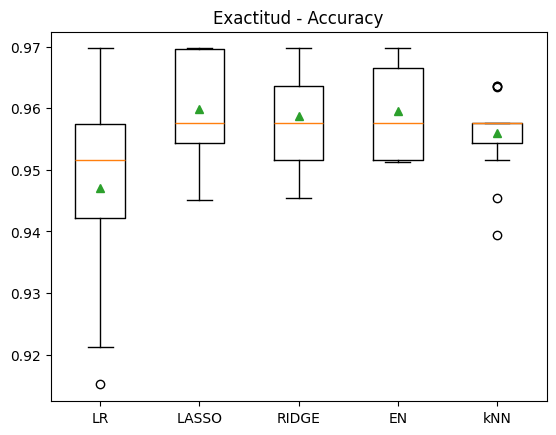

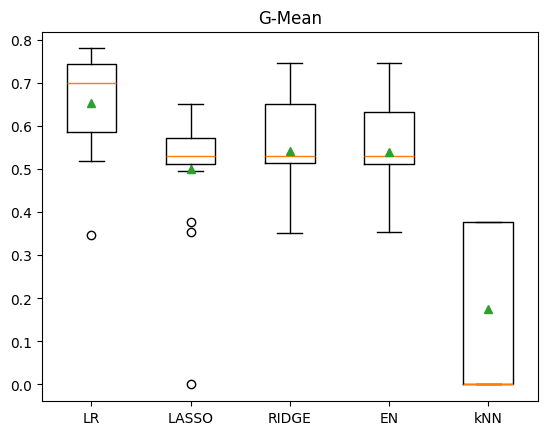

In [22]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* **4a)** Con la exactitud el umbral es 0.9575 (Ejercicio 3c). La regresión logística sin regularización (**LR**, 0.947) y **kNN** (0.956) quedan por debajo, así que están subentrenados con esta métrica. LASSO (0.960), RIDGE (0.959) y EN (0.960) apenas lo superan, por menos de una desviación estándar (≈0.008), así que en la práctica no se distinguen del modelo que siempre dice "no hay derrame". Formalmente no están subentrenados, pero no aportan nada que el modelo ingenuo no haga.

* **4b)** Con la G-mean el umbral es ≈0.51 (Ejercicio 3b). **kNN** (0.174) y **LASSO** (0.501) quedan por debajo y están subentrenados. RIDGE (0.541) y EN (0.540) lo rebasan por muy poco y con desviaciones de ~0.11, así que tampoco son convincentes. El único que se separa claramente es **LR** sin regularización (0.654).

  Lo interesante es que los rankings se invierten: LR es el peor según la exactitud y el mejor según la G-mean. La razón es que, al no tener regularización, se atreve a predecir más derrames; acierta algunos y se equivoca en otros. La exactitud castiga esos errores, porque cada falsa alarma le resta, y premia a los modelos que casi siempre dicen "limpio". Es la misma trampa del 1a vista en números reales. (Los valores pueden variar en el tercer decimal según la versión de scikit-learn.)


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

### **Ejercicio 5 – búsqueda de hiperparámetros**
Primero defino una función auxiliar para crear las regresiones logísticas. A partir de scikit-learn 1.8 el argumento `penalty` está en desuso y genera advertencias, así que la función revisa la versión instalada y construye el modelo equivalente sin warnings en cualquier versión. En la versión 1.8, una regresión "sin penalización" se expresa con un `C` muy grande, porque `C=np.inf` también dispara una advertencia.

In [23]:
# Función auxiliar: crea la regresión logística equivalente sin advertencias en cualquier versión de sklearn.
_version = tuple(int(p) for p in sklearn.__version__.split('.')[:2])
SKLEARN_NUEVO = _version >= (1, 8)

def logistica(tipo, C=1.0, l1_ratio=0.5, **kw):
    """tipo: 'none' (sin regularización), 'l1' (LASSO), 'l2' (RIDGE) o 'en' (Elastic-Net)."""
    if SKLEARN_NUEVO:
        if tipo == 'none':
            return LogisticRegression(C=1e10, **kw)          # equivalente práctico a no regularizar
        if tipo == 'l2':
            return LogisticRegression(C=C, l1_ratio=0.0, **kw)
        if tipo == 'l1':
            return LogisticRegression(C=C, l1_ratio=1.0, solver='liblinear', **kw)
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver='saga', **kw)
    if tipo == 'none':
        return LogisticRegression(penalty=None, **kw)
    if tipo == 'l2':
        return LogisticRegression(penalty='l2', C=C, **kw)
    if tipo == 'l1':
        return LogisticRegression(penalty='l1', C=C, solver='liblinear', **kw)
    return LogisticRegression(penalty='elasticnet', C=C, l1_ratio=l1_ratio, solver='saga', **kw)

print('Versión de scikit-learn:', sklearn.__version__)

Versión de scikit-learn: 1.6.1


In [24]:
# Búsqueda de hiperparámetros con el mismo esquema de validación cruzada de "Código-1".
cv5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

def evalua(modelo):
    pipe = Pipeline(steps=[('ct', columnasTransformer), ('m', modelo)])
    sc = cross_val_score(pipe, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv5, n_jobs=-1)
    return mean(sc), std(sc)

kw = dict(class_weight='balanced', max_iter=10000, random_state=1)
filas = []
filas.append(('LR', 'class_weight=balanced', *evalua(logistica('none', **kw))))
for C in [0.01, 0.03, 0.05, 0.1, 0.3, 1]:
    filas.append(('LASSO', f'C={C}', *evalua(logistica('l1', C=C, **kw))))
    filas.append(('RIDGE', f'C={C}', *evalua(logistica('l2', C=C, **kw))))
    for r in [0.5, 0.75, 0.9]:
        filas.append(('EN', f'C={C}, l1_ratio={r}', *evalua(logistica('en', C=C, l1_ratio=r, **kw))))
for k in [1, 3, 5]:
    for met in ['euclidean', 'manhattan']:
        filas.append(('kNN', f'k={k}, {met}', *evalua(KNeighborsClassifier(n_neighbors=k, metric=met))))

tabla = pd.DataFrame(filas, columns=['modelo', 'hiperparámetros', 'G-mean', 'std'])
# Mejor configuración por modelo:
print(tabla.sort_values('G-mean', ascending=False).groupby('modelo').head(1).round(3).to_string(index=False))

modelo       hiperparámetros  G-mean   std
    EN  C=0.05, l1_ratio=0.9   0.852 0.047
 LASSO                C=0.05   0.849 0.042
 RIDGE                C=0.01   0.817 0.106
    LR class_weight=balanced   0.754 0.120
   kNN        k=1, manhattan   0.497 0.101


Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
LR
G-mean: >> 0.754 (0.120)

LASSO
G-mean: >> 0.849 (0.042)

RIDGE
G-mean: >> 0.817 (0.106)

EN
G-mean: >> 0.852 (0.047)

kNN
G-mean: >> 0.497 (0.101)



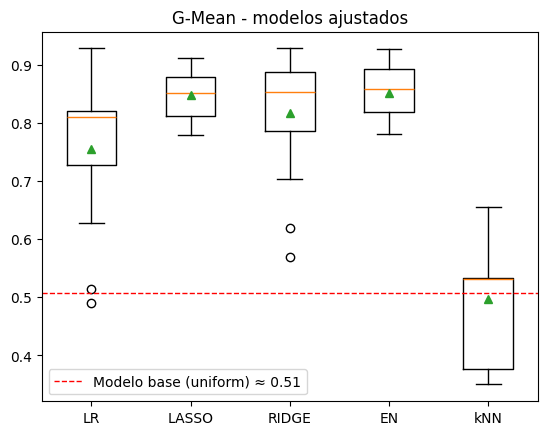

In [25]:
# 5)



print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

def mis_modelos_ajustados():
    modelos, nombres = list(), list()

    # Regresión logística sin regularización, compensando el desbalance con pesos por clase:
    modelos.append(logistica('none', class_weight='balanced', max_iter=10000, random_state=1))
    nombres.append('LR')

    # LASSO (L1): regularización fuerte, se queda con pocas variables relevantes.
    modelos.append(logistica('l1', C=0.05, class_weight='balanced', max_iter=10000, random_state=1))
    nombres.append('LASSO')

    # RIDGE (L2):
    modelos.append(logistica('l2', C=0.01, class_weight='balanced', max_iter=10000, random_state=1))
    nombres.append('RIDGE')

    # Elastic-Net (mezcla L1-L2), cargado hacia L1:
    modelos.append(logistica('en', C=0.05, l1_ratio=0.9, class_weight='balanced', max_iter=10000, random_state=1))
    nombres.append('EN')

    # kNN no tiene class_weight; lo mejor encontrado fue k=1 con distancia Manhattan.
    modelos.append(KNeighborsClassifier(n_neighbors=1, metric='manhattan'))
    nombres.append('kNN')

    return modelos, nombres


modelos, nombres = mis_modelos_ajustados()
resultados_aj = list()
cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

for i in range(len(modelos)):
    pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelos[i])])
    scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv1, n_jobs=-1)
    resultados_aj.append(scores)
    print(nombres[i])
    print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores), np.nanstd(scores)))
    print()

plt.boxplot(resultados_aj, tick_labels=nombres, showmeans=True)
plt.axhline(0.508, color='red', linestyle='--', linewidth=1, label='Modelo base (uniform) ≈ 0.51')
plt.title("G-Mean - modelos ajustados")
plt.legend(loc='lower left')
plt.show()

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++

**Comentario del Ejercicio 5:**

* El cambio más grande vino de `class_weight='balanced'`. Ese argumento le da a cada clase un peso inversamente proporcional a su frecuencia: con ~36 derrames y ~788 imágenes limpias en `Xtv`, cada error en un derrame pesa unas 22 veces más que un error en mar limpio. Sin esto el modelo "aprende" que conviene decir siempre limpio.
* El segundo ajuste fue la fuerza de la regularización (`C` pequeño = regularización más fuerte). Con solo 36 positivos y 47 variables, el modelo se sobreajusta fácilmente a los pocos derrames; regularizar fuerte lo hace más estable. LASSO pasó de 0.501 a ~0.85 y RIDGE de 0.541 a ~0.82. Elastic-Net con `l1_ratio=0.9` quedó prácticamente empatado con LASSO, lo que sugiere que buena parte de las 47 variables sobra.
* kNN es el que no mejora: no tiene `class_weight` y, cuando `k>1`, el voto entre vecinos casi siempre lo gana la clase mayoritaria. Con `k=1` llega a ~0.50, todavía por debajo del modelo base. Para kNN haría falta balancear los datos (sobremuestreo o submuestreo), que es lo que veremos en las próximas semanas.

# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [26]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.

# Elegimos Elastic-Net: tuvo la mejor G-mean promedio en validación cruzada (Ejercicio 5).
mejor_modelo = Pipeline(steps=[('ct', columnasTransformer),
                               ('m', logistica('en', C=0.05, l1_ratio=0.9, class_weight='balanced',
                                               max_iter=10000, random_state=1))])

mejor_modelo.fit(Xtrain, np.ravel(ytrain))

ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)

dif = geometric_mean_score(np.ravel(ytrain), ytrain_hat) - geometric_mean_score(np.ravel(yval), yval_hat)
print('Diferencia G-mean (Train - Val): %.4f  ->  %s' % (dif, 'sin sobreentrenamiento' if dif <= 0.03 else 'revisar sobreentrenamiento'))
print()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

Diferencia G-mean (Train - Val): -0.0756  ->  sin sobreentrenamiento

G-mean del mejor modelo-Train: 0.8619
G-mean del mejor modelo-Val: 0.9375

Exactitud del mejor modelo-Train: 0.8346
Exactitud del mejor modelo-Val: 0.8848

Matriz de Confusión con Validación:
 [[138  19]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.83636364 0.11515152]
 [0.         0.04848485]]


**Comentario del Ejercicio 6a:** el mejor modelo es Elastic-Net (`C=0.05`, `l1_ratio=0.9`, `class_weight='balanced'`). En validación detecta los 8 derrames (cero falsos negativos) con 19 falsas alarmas de 157 imágenes limpias. La G-mean de entrenamiento (≈0.86) es *menor* que la de validación (≈0.94), así que la diferencia es negativa y no hay sobreentrenamiento: el modelo no memorizó el entrenamiento. Que validación salga más alta se explica por su tamaño: tiene solo 8 derrames y, en este caso, el modelo los acertó todos; con tan pocos casos, un solo derrame cambia la sensibilidad en 12.5 puntos. Por eso no conviene leer ese 0.94 como el desempeño "real" esperado, sino como un resultado con mucha incertidumbre.

Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6b)** En "Código-1" los modelos tenían exactitudes alrededor de 0.95–0.96, y ahora el mejor modelo baja a ≈0.88 en validación. No es que el modelo haya empeorado, es que cambió lo que estaba optimizando. Los modelos de "Código-1" ganaban exactitud diciendo casi siempre "no hay derrame", que es la decisión segura cuando el 95% de las imágenes están limpias. Con `class_weight='balanced'`, en cambio, equivocarse con un derrame cuesta unas 22 veces más que equivocarse con mar limpio, así que el modelo prefiere levantar una alarma de más que dejar pasar un derrame. El resultado es que detecta los 8 derrames de validación, pero a cambio genera 19 falsas alarmas, y cada una le resta a la exactitud. Es el intercambio que buscábamos: perder exactitud para ganar sensibilidad, y por eso la G-mean sube de ~0.5–0.65 a ~0.85 en validación cruzada. Ver el 1a: la exactitud alta de antes era engañosa.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

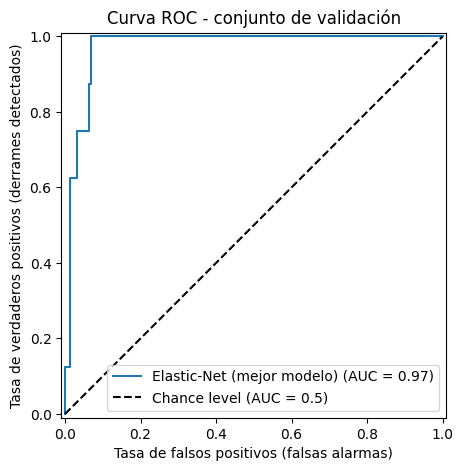

In [27]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='Elastic-Net (mejor modelo)',
                               plot_chance_level=True, ax=ax)
ax.set_title('Curva ROC - conjunto de validación')
ax.set_xlabel('Tasa de falsos positivos (falsas alarmas)')
ax.set_ylabel('Tasa de verdaderos positivos (derrames detectados)')
plt.show()

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

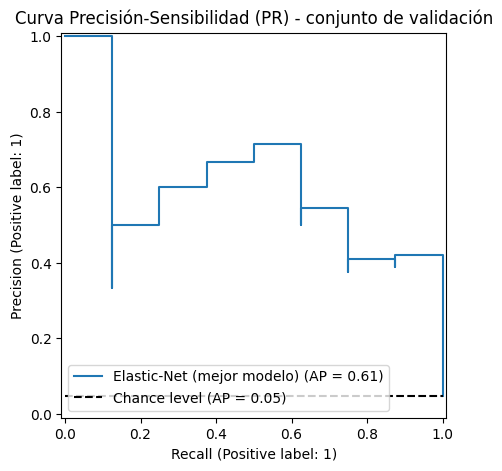

Área bajo la curva PR (trapecio): 0.576
Nivel de azar (proporción de derrames en validación): 0.048


In [28]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(mejor_modelo, Xval, np.ravel(yval), name='Elastic-Net (mejor modelo)',
                                      plot_chance_level=True, ax=ax)
ax.set_title('Curva Precisión-Sensibilidad (PR) - conjunto de validación')
plt.show()

# AP es el resumen que muestra sklearn; también calculamos el área por la regla del trapecio:
proba_val = mejor_modelo.predict_proba(Xval)[:, 1]
prec, rec, _ = precision_recall_curve(np.ravel(yval), proba_val)
print('Área bajo la curva PR (trapecio): %.3f' % auc(rec, prec))
print('Nivel de azar (proporción de derrames en validación): %.3f' % np.mean(yval))

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* **6e)** Las dos curvas cuentan historias distintas y ahí está lo útil:
  * **ROC (AUC ≈ 0.97 contra 0.50 del azar).** El modelo ordena muy bien las imágenes: si tomamos al azar una con derrame y otra limpia, casi siempre le da más probabilidad de derrame a la que sí lo tiene. Visto así, parece casi perfecto.
  * **PR (AP ≈ 0.61 contra 0.048 del azar).** Esta curva es más honesta en un problema desbalanceado, porque mide la precisión: de las alarmas que levanta el modelo, cuántas son derrames de verdad. Es unas 12 veces mejor que el azar, pero lejos de 1. Para detectar todos los derrames hay que aceptar bastantes falsas alarmas; con el umbral de 0.5, cerca de 7 de cada 10 alarmas son *look-alikes*.
  * ¿Por qué la diferencia? La ROC usa en el eje horizontal la tasa de falsos positivos, que se divide entre 157 imágenes limpias, así que 19 falsas alarmas parecen poca cosa (12%). La PR las compara contra solo 8 derrames, y ahí sí pesan. Por eso, con clases desbalanceadas, la curva PR da una idea más realista del costo operativo (Saito y Rehmsmeier, 2015).
  * **En el contexto del problema:** el modelo funciona muy bien como filtro, porque deja pasar muy pocos derrames y descarta la mayor parte del mar limpio, pero no como juez final: todavía hace falta alguien que revise las alarmas antes de mandar recursos. Además, con solo 8 derrames en validación las curvas son escalonadas y los valores tienen mucha incertidumbre; habría que confirmarlos con el conjunto de prueba.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [29]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.88      1.00      0.94      0.94      0.87       157
class 1:oil-spill       0.30      1.00      0.88      0.46      0.94      0.89         8

      avg / total       0.97      0.88      0.99      0.91      0.94      0.87       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





In [30]:
# Respuesta Ejercicio 7:

# 7a) Función para calcular el Costo Total Esperado en distintos umbrales (solo con el conjunto de validación).

COSTO_FN = 1_000_000   # derrame no detectado
COSTO_FP = 15_000      # falsa alarma (inspección con helicóptero)

def costo_total_esperado(y_real, probabilidades, umbrales, costo_fn=COSTO_FN, costo_fp=COSTO_FP):
    """Para cada umbral convierte las probabilidades en predicciones (1 si p >= umbral)
    y calcula el costo total = FN * costo_fn + FP * costo_fp. Devuelve un DataFrame."""
    y_real = np.ravel(y_real)
    filas = []
    for u in umbrales:
        y_pred = (probabilidades >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
        filas.append({'umbral': round(u, 2), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                      'costo_total': fn * costo_fn + fp * costo_fp,
                      'g_mean': geometric_mean_score(y_real, y_pred)})
    return pd.DataFrame(filas)

umbrales = np.round(np.arange(0.10, 0.901, 0.01), 2)
proba_val = mejor_modelo.predict_proba(Xval)[:, 1]
tabla_costos = costo_total_esperado(yval, proba_val, umbrales)

mejor = tabla_costos.loc[tabla_costos['costo_total'].idxmin()]
print('Umbral óptimo: %.2f  ->  Costo total: $%s USD' % (mejor['umbral'], f"{mejor['costo_total']:,.0f}"))
print(tabla_costos.iloc[::5].to_string(index=False))

Umbral óptimo: 0.66  ->  Costo total: $165,000 USD
 umbral  TN  FP  FN  TP  costo_total   g_mean
   0.10  61  96   0   8      1440000 0.623326
   0.15  86  71   0   8      1065000 0.740115
   0.20  98  59   0   8       885000 0.790066
   0.25 110  47   0   8       705000 0.837041
   0.30 119  38   0   8       570000 0.870610
   0.35 121  36   0   8       540000 0.877896
   0.40 126  31   0   8       465000 0.895850
   0.45 132  25   0   8       375000 0.916932
   0.50 138  19   0   8       285000 0.937540
   0.55 140  17   0   8       255000 0.944309
   0.60 143  14   0   8       210000 0.954373
   0.65 145  12   0   8       180000 0.961024
   0.70 147  10   2   6      2150000 0.837991
   0.75 148   9   2   6      2135000 0.840837
   0.80 152   5   2   6      2075000 0.852124
   0.85 155   2   4   4      4030000 0.702588
   0.90 155   2   5   3      5030000 0.608459


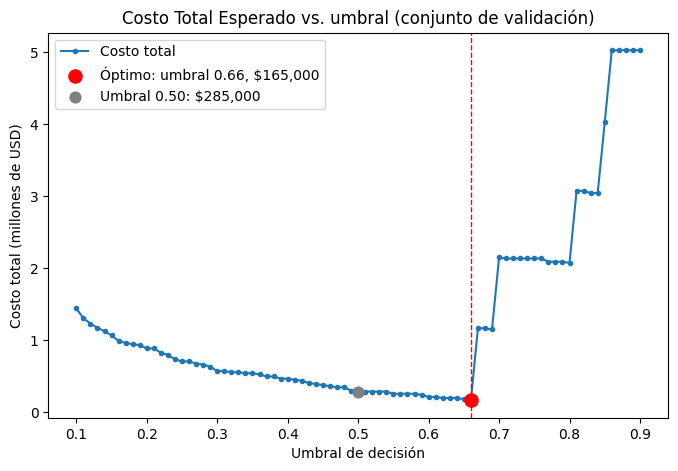

In [31]:
# 7b) Gráfica del costo total contra el umbral.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabla_costos['umbral'], tabla_costos['costo_total'] / 1e6, marker='.', label='Costo total')
ax.scatter(mejor['umbral'], mejor['costo_total'] / 1e6, color='red', s=90, zorder=3,
           label=f"Óptimo: umbral {mejor['umbral']:.2f}, ${mejor['costo_total']:,.0f}")
costo_05 = tabla_costos.loc[tabla_costos['umbral'] == 0.5, 'costo_total'].iloc[0]
ax.scatter(0.5, costo_05 / 1e6, color='gray', s=60, zorder=3, label=f"Umbral 0.50: ${costo_05:,.0f}")
ax.axvline(mejor['umbral'], color='red', linestyle='--', linewidth=1)
ax.set_xlabel('Umbral de decisión')
ax.set_ylabel('Costo total (millones de USD)')
ax.set_title('Costo Total Esperado vs. umbral (conjunto de validación)')
ax.legend()
plt.show()

In [32]:
# 7c) Comparación entre el umbral predeterminado (0.5) y el umbral óptimo.
for u in [0.5, mejor['umbral']]:
    y_pred_u = (proba_val >= u).astype(int)
    fila = tabla_costos.loc[tabla_costos['umbral'] == round(u, 2)].iloc[0]
    print(f'Umbral = {u:.2f}')
    print('Matriz de confusión (filas = real, columnas = predicción):')
    print(confusion_matrix(np.ravel(yval), y_pred_u))
    print('G-mean = %.4f | Costo total = $%s USD\n' % (geometric_mean_score(np.ravel(yval), y_pred_u),
                                                       f"{fila['costo_total']:,.0f}"))

# Probabilidad más baja que el modelo le asignó a un derrame real (margen de seguridad del umbral):
print('Probabilidad mínima asignada a un derrame real en validación: %.3f' % proba_val[np.ravel(yval) == 1].min())

Umbral = 0.50
Matriz de confusión (filas = real, columnas = predicción):
[[138  19]
 [  0   8]]
G-mean = 0.9375 | Costo total = $285,000 USD

Umbral = 0.66
Matriz de confusión (filas = real, columnas = predicción):
[[146  11]
 [  0   8]]
G-mean = 0.9643 | Costo total = $165,000 USD

Probabilidad mínima asignada a un derrame real en validación: 0.664


### **Respuestas Ejercicio 7d y 7e**

* **7d)** Sí vale la pena cambiarlo, pero con cuidado. Con el umbral de 0.5 el modelo genera 19 falsas alarmas y ningún derrame se le escapa: $285,000 USD. Con el umbral óptimo de **0.66** siguen detectándose los 8 derrames y las falsas alarmas bajan a 11, con un costo de **$165,000 USD**, un ahorro de $120,000 (42%). La G-mean también mejora, de 0.938 a 0.964. Bajar el umbral por debajo de 0.5 no ayuda, porque ya se detectan todos los derrames y solo se agregan alarmas.

  La estrategia cambia en el sentido de que el umbral deja de ser una convención (0.5) y pasa a ser una decisión de negocio. Pero la gráfica también muestra lo peligroso: la curva tiene un "precipicio". El derrame con menor probabilidad recibió 0.664, apenas arriba del umbral óptimo, y con 0.70 ya se escapan 2 derrames y el costo salta a más de $2.1 millones. Un solo falso negativo cuesta lo mismo que 67 falsas alarmas. Con solo 8 derrames en validación, ese 0.66 está demasiado pegado al borde. Mi recomendación sería un umbral más conservador, de alrededor de **0.60** (14 falsas alarmas, $210,000), que todavía ahorra $75,000 frente al 0.5 pero deja margen. Antes de desplegar lo confirmaría con el conjunto de prueba y lo recalibraría conforme lleguen más casos reales.

  Un detalle teórico: si las probabilidades estuvieran bien calibradas, el umbral óptimo saldría de la razón de costos, $\frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{15{,}000}{1{,}015{,}000} \approx 0.015$ (Elkan, 2001). Aquí no aplica directo porque `class_weight='balanced'` ya movió las probabilidades hacia la clase positiva, así que tiene más sentido buscar el umbral de forma empírica, como se hizo.

* **7e)** LLM utilizado: **Claude (Anthropic), modelo Claude Opus 5.5**, a través de claude.ai.

  Prompt utilizado (junto con el notebook, el archivo `oil_spill.csv` y las instrucciones de la actividad):

  > *"Qué tal te anexo la rúbrica de esta semana, con las instrucciones y el data set me ayudas a contestarla y darme una explicación de cada uno de los puntos como en bullet points de lo más relevante"*

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

**Para:** Director de Operaciones
**De:** Ingeniero líder de IA
**Asunto:** Por qué el 96% de "exactitud" no es lo que parece y cómo proponemos usar el modelo

El reporte de la herramienta de BI dice que el modelo acierta el 96% de las veces. El número es real, pero engaña. De cada 100 imágenes satelitales, solo unas 4 tienen derrame. Un sistema que respondiera siempre "el mar está limpio", sin analizar nada, también acertaría el 96%, y no detectaría un solo derrame. Ese sistema ingenuo es justo el peligro: cada derrame que deja pasar puede costar alrededor de un millón de dólares entre limpieza, multas y daño ambiental.

Por eso evaluamos el modelo con una medida que exige acertar en las dos cosas a la vez: encontrar los derrames y no llenarnos de falsas alarmas. Con ese criterio, nuestro modelo detectó todos los derrames en nuestras pruebas internas (8 de 8). El costo es que también levanta falsas alarmas: manchas que se parecen al petróleo, como algas o zonas de mar en calma. Con el ajuste que proponemos, aparecen unas 14 falsas alarmas por cada 165 imágenes. Cada una cuesta unos 15,000 dólares si se manda un helicóptero a revisarla.

Entonces la pregunta no es si el modelo es "casi perfecto", sino quién filtra esas falsas alarmas antes de gastar en un vuelo. Si el modelo despacha helicópteros solo, pagamos todas las inspecciones innecesarias. Si un analista revisa primero la imagen, puede descartar en minutos varias de esas manchas.

**Propuesta de despliegue (humano en el circuito):**

1. **El modelo revisa el 100% de las imágenes** y descarta automáticamente las de probabilidad muy baja.
2. **Los dos analistas revisan solo las alertas.** Confirman las claras, descartan los parecidos evidentes y solo entonces se autoriza el vuelo.
3. **Los casos dudosos se escalan** a inspección, siguiendo el criterio de que un derrame no detectado cuesta lo mismo que unas 67 inspecciones.
4. **Cada decisión de los analistas se registra** para reentrenar el modelo cada trimestre y reducir las falsas alarmas con el tiempo.
5. **Piloto de 3 meses en paralelo**, comparando lo que detecta el modelo contra los analistas antes de cambiar el proceso.

En resumen: el modelo no reemplaza a los analistas, les quita el trabajo repetitivo. Despedirlos nos dejaría con más vuelos innecesarios y sin nadie que detecte cuándo se equivoca el modelo.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

La lección principal de esta actividad es que, con clases desbalanceadas, la métrica decide todo lo demás. Con la exactitud, el mejor "modelo" era uno que no detectaba nada; con la G-mean, ese mismo modelo vale cero. Y los rankings se invirtieron: la regresión logística sin regularizar fue la peor por exactitud y la mejor por G-mean en "Código-1".

El segundo aprendizaje es que el código que corre sin errores no es lo mismo que un buen modelo. Con los valores predeterminados, casi todos los modelos quedaron pegados al modelo base. Bastó con `class_weight='balanced'` y una regularización fuerte para pasar de ~0.5 a ~0.85 de G-mean, sin ninguna técnica de balanceo adicional. kNN fue la excepción y deja claro por qué en las próximas semanas veremos sobremuestreo y submuestreo.

También me quedo con la diferencia entre las curvas ROC y PR. La ROC decía 0.97 y la PR mostró que la mayoría de las alarmas eran falsas. Para el negocio, la segunda es la que importa.

Por último, el ejercicio de costos conecta directamente con mi experiencia en automatización para la industria automotriz. En inspección de calidad hablamos de *escapes* (una pieza defectuosa que llega al cliente, nuestro falso negativo) y de *rechazos falsos* (una pieza buena que se retira de la línea, nuestro falso positivo). Nunca cuestan lo mismo, y el umbral de una estación de visión se ajusta según ese costo, no a 0.5. Lo mismo aplica aquí: el umbral de 0.66 minimiza el costo en validación, pero queda tan cerca del derrame con menor probabilidad que en planta yo dejaría un margen de seguridad, igual que se hace con cualquier límite de proceso.

### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **Referencias**

Box, G. E. P., y Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Elkan, C. (2001). The foundations of cost-sensitive learning. En *Proceedings of the 17th International Joint Conference on Artificial Intelligence (IJCAI)* (pp. 973–978). https://www.ijcai.org/Proceedings/01/IJCAI-2001-k.pdf

Falcón Morales, L. E. (2026). *Actividad: Problema de clasificación con datos desbalanceados – Oil-Spill* [Notebook de la actividad, curso TC4058.10]. Tecnológico de Monterrey.

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3a ed., cap. 3). O'Reilly Media.

Huyen, C. (2022). *Designing machine learning systems* (cap. 4, sección "Class Imbalance"). O'Reilly Media.

Kubat, M., Holte, R. C., y Matwin, S. (1998). Machine learning for the detection of oil spills in satellite radar images. *Machine Learning, 30*(2–3), 195–215. https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

Lemaître, G., Nogueira, F., y Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5. https://jmlr.org/papers/v18/16-365.html

Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

scikit-learn developers. (s.f.). *DummyClassifier*, *LogisticRegression*, *RocCurveDisplay* y *PrecisionRecallDisplay*. Scikit-learn. https://scikit-learn.org/stable/api/index.html

Wu, X., Xiao, L., Sun, Y., Zhang, J., Ma, T., y He, L. (2022). A survey of human-in-the-loop for machine learning. *Future Generation Computer Systems, 135*, 364–381. https://arxiv.org/abs/2108.00941

Yeo, I.-K., y Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954

---

**Declaración de uso de IA**

Anthropic. (2026). Claude [modelo de lenguaje grande], utilizado para organizar argumentos, revisar conceptos y generar el código de la función de costos y la gráfica del Ejercicio 7. https://claude.ai/

Microsoft. (2026). GitHub Copilot [asistente de programación], utilizado para corrección de código y para acomodar texto junto al mismo. https://github.com/features/copilot

---

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**